# Problem 1: Smart Home Energy Consumption Analysis Using Bayesian Networks
## Part A: Expert Bayesian Network
### 1 & 2. Constructing the Network and Verifying CPTs
We represent the six variables in topological order: `W` (Weather), `D` (Day Type), `O` (Occupancy), `A` (AC Usage), `L` (Appliance Load), and `E` (Energy Consumption), and check that every parent configuration's probability distribution sums to `1.0`.

In [9]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

states = {
    'W': ['Hot', 'Mild', 'Cold'],
    'D': ['Weekday', 'Weekend'],
    'O': ['High', 'Low'],
    'A': ['On', 'Off'],
    'L': ['Heavy', 'Light'],
    'E': ['High', 'Low']
}

deps = {
    'W': [],
    'D': [],
    'O': ['D'],
    'A': ['W', 'O'],
    'L': ['O'],
    'E': ['A', 'L']
}

nodes = ['W', 'D', 'O', 'A', 'L', 'E']

cpts = {
    'W': {
        (): {'Hot': 0.50, 'Mild': 0.30, 'Cold': 0.20}
    },
    'D': {
        (): {'Weekday': 0.70, 'Weekend': 0.30}
    },
    'O': {
        ('Weekday',): {'High': 0.45, 'Low': 0.55},
        ('Weekend',): {'High': 0.80, 'Low': 0.20}
    },
    'A': {
        ('Hot', 'High'): {'On': 0.90, 'Off': 0.10},
        ('Hot', 'Low'): {'On': 0.60, 'Off': 0.40},
        ('Mild', 'High'): {'On': 0.40, 'Off': 0.60},
        ('Mild', 'Low'): {'On': 0.15, 'Off': 0.85},
        ('Cold', 'High'): {'On': 0.10, 'Off': 0.90},
        ('Cold', 'Low'): {'On': 0.05, 'Off': 0.95}
    },
    'L': {
        ('High',): {'Heavy': 0.75, 'Light': 0.25},
        ('Low',): {'Heavy': 0.35, 'Light': 0.65}
    },
    'E': {
        ('On', 'Heavy'): {'High': 0.92, 'Low': 0.08},
        ('On', 'Light'): {'High': 0.68, 'Low': 0.32},
        ('Off', 'Heavy'): {'High': 0.55, 'Low': 0.45},
        ('Off', 'Light'): {'High': 0.12, 'Low': 0.88}
    }
}

def verify(net):
    ok = True
    for n, tbl in net.items():
        for cfg, dist in tbl.items():
            tot = sum(dist.values())
            if not np.isclose(tot, 1.0):
                ok = False
            lbl = ', '.join(cfg) if cfg else 'Prior'
            print(f"{n} ({lbl}): sum = {tot:.4f}")
    return ok

print("All CPTs valid:", verify(cpts))

W (Prior): sum = 1.0000
D (Prior): sum = 1.0000
O (Weekday): sum = 1.0000
O (Weekend): sum = 1.0000
A (Hot, High): sum = 1.0000
A (Hot, Low): sum = 1.0000
A (Mild, High): sum = 1.0000
A (Mild, Low): sum = 1.0000
A (Cold, High): sum = 1.0000
A (Cold, Low): sum = 1.0000
L (High): sum = 1.0000
L (Low): sum = 1.0000
E (On, Heavy): sum = 1.0000
E (On, Light): sum = 1.0000
E (Off, Heavy): sum = 1.0000
E (Off, Light): sum = 1.0000
All CPTs valid: True


### 3. Visualizing the Bayesian Network

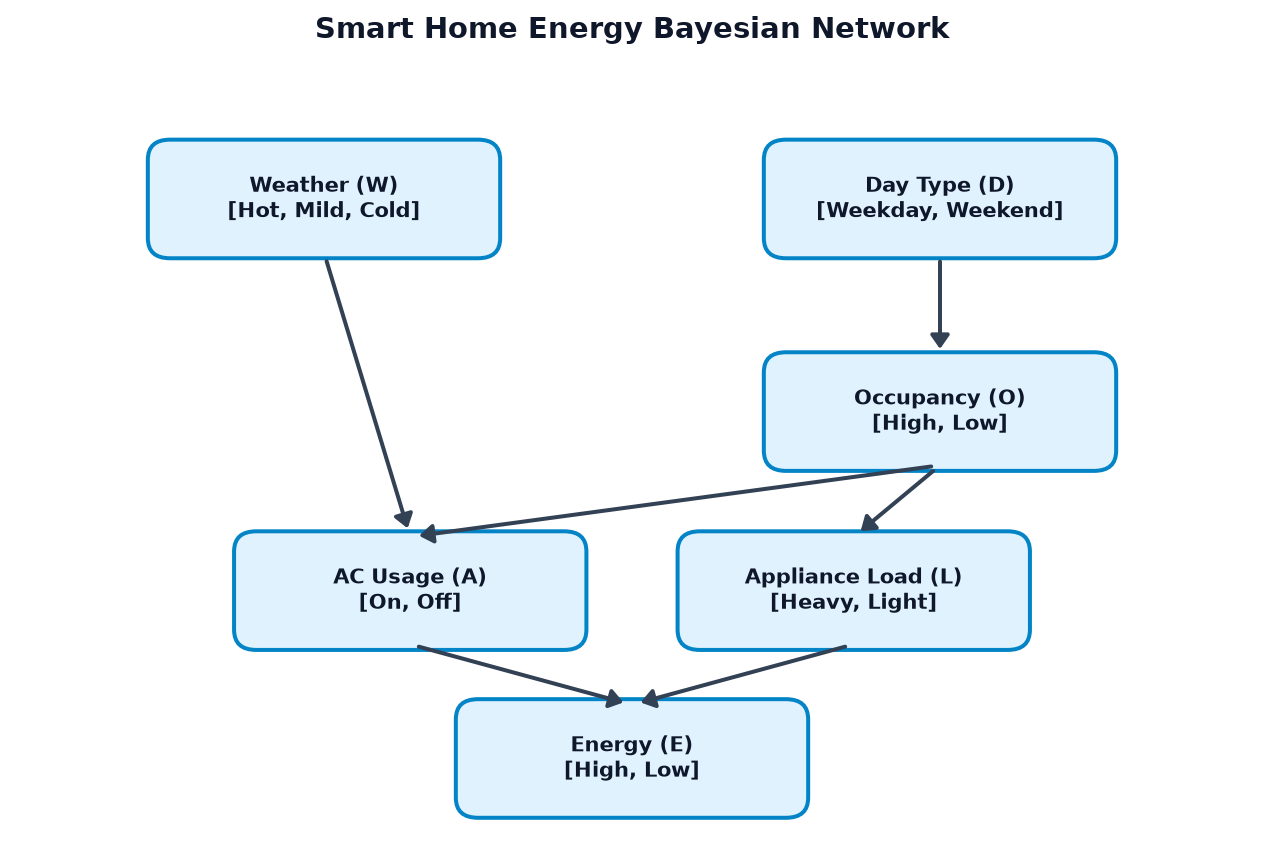

In [10]:
def draw_net(fname='bn_graph.png'):
    fig, ax = plt.subplots(figsize=(8, 5.5), dpi=160)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 7)
    ax.axis('off')

    pos = {
        'W': (2.5, 5.8),
        'D': (7.5, 5.8),
        'O': (7.5, 3.9),
        'A': (3.2, 2.3),
        'L': (6.8, 2.3),
        'E': (5.0, 0.8)
    }

    titles = {
        'W': 'Weather (W)\n[Hot, Mild, Cold]',
        'D': 'Day Type (D)\n[Weekday, Weekend]',
        'O': 'Occupancy (O)\n[High, Low]',
        'A': 'AC Usage (A)\n[On, Off]',
        'L': 'Appliance Load (L)\n[Heavy, Light]',
        'E': 'Energy (E)\n[High, Low]'
    }

    for ch, pars in deps.items():
        x2, y2 = pos[ch]
        for p in pars:
            x1, y1 = pos[p]
            ax.annotate(
                '', xy=(x2, y2 + 0.48), xytext=(x1, y1 - 0.48),
                arrowprops=dict(arrowstyle='-|>,head_width=0.35,head_length=0.5',
                                lw=1.8, color='#334155', shrinkA=4, shrinkB=4)
            )

    for n, (x, y) in pos.items():
        box = mpatches.FancyBboxPatch(
            (x - 1.35, y - 0.45), 2.7, 0.9,
            boxstyle='round,pad=0.08,rounding_size=0.18',
            facecolor='#e0f2fe', edgecolor='#0284c7', linewidth=1.8
        )
        ax.add_patch(box)
        ax.text(x, y, titles[n], ha='center', va='center',
                fontsize=9.5, fontweight='bold', color='#0f172a')

    ax.set_title('Smart Home Energy Bayesian Network',
                 fontsize=13, fontweight='bold', pad=12, color='#0f172a')
    plt.tight_layout()
    plt.savefig(fname, bbox_inches='tight')
    plt.show()

draw_net('bn_graph.png')

### 4. Exact Inference Queries (Q1 – Q7)

In [11]:
def joint(net, row):
    p = 1.0
    for n in nodes:
        cfg = tuple(row[par] for par in deps[n])
        p *= net[n][cfg][row[n]]
    return p

def prob(net, query, ev=None):
    if ev is None:
        ev = {}
    top = 0.0
    bot = 0.0
    for combo in itertools.product(*(states[n] for n in nodes)):
        row = dict(zip(nodes, combo))
        if all(row[k] == v for k, v in ev.items()):
            jp = joint(net, row)
            bot += jp
            if all(row[k] == v for k, v in query.items()):
                top += jp
    return top / bot if bot > 0 else 0.0

def queries(net):
    return {
        'Q1': prob(net, {'E': 'High'}),
        'Q2': prob(net, {'E': 'High'}, {'W': 'Hot'}),
        'Q3': prob(net, {'E': 'High'}, {'D': 'Weekend'}),
        'Q4': prob(net, {'E': 'High'}, {'W': 'Cold', 'O': 'High'}),
        'Q5': prob(net, {'W': 'Hot'}, {'E': 'High'}),
        'Q6': prob(net, {'A': 'On'}, {'E': 'High'}),
        'Q7': prob(net, {'A': 'On'}, {'E': 'High', 'L': 'Heavy'})
    }

exp_q = queries(cpts)
for k, v in exp_q.items():
    print(f"{k}: {v:.6f}")

Q1: 0.580631
Q2: 0.706266
Q3: 0.640199
Q4: 0.484250
Q5: 0.608188
Q6: 0.692867
Q7: 0.649899


### 5. Comparing Q6 and Q7 (Explaining Away)
* **Q6:** $P(A = \text{On} \mid E = \text{High}) = 0.692867$
* **Q7:** $P(A = \text{On} \mid E = \text{High}, L = \text{Heavy}) = 0.649899$

When we only observe high energy consumption ($E = \text{High}$), both parents in the collider $A \rightarrow E \leftarrow L$ become much more likely as potential causes. Once we additionally observe that the appliance load is heavy ($L = \text{Heavy}$), that heavy load already accounts for a substantial portion of the high energy consumption ($P(E = \text{High} \mid A = \text{Off}, L = \text{Heavy}) = 0.55$). Consequently, heavy appliance usage **explains away** the high energy consumption, lowering the posterior probability that the air conditioner was also running from `0.6929` down to `0.6499`.

### 6. Calculating Q1 by Hand
We marginalize over the network from top to bottom:
1. **Occupancy marginal $P(O)$:**
   $$P(O = \text{High}) = 0.70(0.45) + 0.30(0.80) = 0.315 + 0.240 = 0.555, \quad P(O = \text{Low}) = 0.445$$
2. **AC Usage given Occupancy $P(A = \text{On} \mid O)$ (marginalizing out $W$):**
   $$P(A = \text{On} \mid O = \text{High}) = 0.50(0.90) + 0.30(0.40) + 0.20(0.10) = 0.45 + 0.12 + 0.02 = 0.59$$
   $$P(A = \text{On} \mid O = \text{Low}) = 0.50(0.60) + 0.30(0.15) + 0.20(0.05) = 0.30 + 0.045 + 0.01 = 0.355$$
3. **Energy Consumption given Occupancy $P(E = \text{High} \mid O)$:**
   * For $O = \text{High}$ ($P(L = \text{Heavy} \mid \text{High}) = 0.75$):
     $$P(E = \text{High} \mid O = \text{High}) = (0.59)(0.75)(0.92) + (0.59)(0.25)(0.68) + (0.41)(0.75)(0.55) + (0.41)(0.25)(0.12) = 0.688825$$
   * For $O = \text{Low}$ ($P(L = \text{Heavy} \mid \text{Low}) = 0.35$):
     $$P(E = \text{High} \mid O = \text{Low}) = (0.355)(0.35)(0.92) + (0.355)(0.65)(0.68) + (0.645)(0.35)(0.55) + (0.645)(0.65)(0.12) = 0.4456925$$
4. **Final summation for $P(E = \text{High})$:**
   $$P(E = \text{High}) = 0.555(0.688825) + 0.445(0.4456925) = 0.382297875 + 0.1983331625 = \mathbf{0.5806310375}$$

In [12]:
po_hi = 0.70 * 0.45 + 0.30 * 0.80
po_lo = 1.0 - po_hi
pa_hi = 0.50 * 0.90 + 0.30 * 0.40 + 0.20 * 0.10
pa_lo = 0.50 * 0.60 + 0.30 * 0.15 + 0.20 * 0.05
pe_hi = (
    pa_hi * 0.75 * 0.92 +
    pa_hi * 0.25 * 0.68 +
    (1 - pa_hi) * 0.75 * 0.55 +
    (1 - pa_hi) * 0.25 * 0.12
)
pe_lo = (
    pa_lo * 0.35 * 0.92 +
    pa_lo * 0.65 * 0.68 +
    (1 - pa_lo) * 0.35 * 0.55 +
    (1 - pa_lo) * 0.65 * 0.12
)
q1_hand = po_hi * pe_hi + po_lo * pe_lo
print(f"Hand Q1: {q1_hand:.6f} | Code Q1: {exp_q['Q1']:.6f} | Match: {np.isclose(q1_hand, exp_q['Q1'])}")

Hand Q1: 0.580631 | Code Q1: 0.580631 | Match: True


## Part B: Conditional Independence Analysis

1. **$\text{Weather} \perp \text{DayType}$ — HOLDS (Independent)**
   * **Paths:** $W \rightarrow A \leftarrow O \leftarrow D$ and $W \rightarrow A \rightarrow E \leftarrow L \leftarrow O \leftarrow D$.
   * **d-Separation:** With no conditioning variables ($\emptyset$), the first path is blocked at the collider $W \rightarrow A \leftarrow O$ (neither $A$ nor its descendant $E$ is observed), and the second path is blocked at the collider $A \rightarrow E \leftarrow L$.
2. **$\text{Weather} \perp \text{DayType} \mid \text{EnergyConsumption}$ — DOES NOT HOLD (Dependent)**
   * **Paths:** $W \rightarrow A \leftarrow O \leftarrow D$ and $W \rightarrow A \rightarrow E \leftarrow L \leftarrow O \leftarrow D$.
   * **d-Separation:** Conditioning on $E$ observes a descendant of collider $A$ on the first path (and directly observes collider $E$ on the second path) while non-colliders $O, A, L$ are unobserved, opening active trails between $W$ and $D$.
3. **$\text{Weather} \perp \text{ApplianceLoad} \mid \text{Occupancy}$ — HOLDS (Independent)**
   * **Paths:** $W \rightarrow A \leftarrow O \rightarrow L$ and $W \rightarrow A \rightarrow E \leftarrow L$.
   * **d-Separation:** Conditioning on $O$ blocks the fork $A \leftarrow O \rightarrow L$ on the first path (and $A$ is also an unobserved collider), while the second path remains blocked at the unobserved collider $A \rightarrow E \leftarrow L$.

In [13]:
print(f"1. P(W=Hot) = {prob(cpts, {'W': 'Hot'}):.6f} vs P(W=Hot | D=Weekend) = {prob(cpts, {'W': 'Hot'}, {'D': 'Weekend'}):.6f}")
print(f"2. P(W=Hot | E=High) = {prob(cpts, {'W': 'Hot'}, {'E': 'High'}):.6f} vs P(W=Hot | E=High, D=Weekend) = {prob(cpts, {'W': 'Hot'}, {'E': 'High', 'D': 'Weekend'}):.6f}")
print(f"3. P(W=Hot | O=High) = {prob(cpts, {'W': 'Hot'}, {'O': 'High'}):.6f} vs P(W=Hot | O=High, L=Heavy) = {prob(cpts, {'W': 'Hot'}, {'O': 'High', 'L': 'Heavy'}):.6f}")

1. P(W=Hot) = 0.500000 vs P(W=Hot | D=Weekend) = 0.500000
2. P(W=Hot | E=High) = 0.608188 vs P(W=Hot | E=High, D=Weekend) = 0.599751
3. P(W=Hot | O=High) = 0.500000 vs P(W=Hot | O=High, L=Heavy) = 0.500000


## Part C: Synthetic Data Generation
We implement ancestral sampling by visiting `['W', 'D', 'O', 'A', 'L', 'E']` in topological order using fixed random seed **`seed = 5`** for $N = 500$, $5000$, and $20000$.

In [14]:
def sample(net, size, seed=5):
    rng = np.random.default_rng(seed)
    data = []
    for _ in range(size):
        row = {}
        for n in nodes:
            cfg = tuple(row[par] for par in deps[n])
            dist = net[n][cfg]
            opts = states[n]
            ps = [dist[o] for o in opts]
            row[n] = rng.choice(opts, p=ps)
        data.append(row)
    return pd.DataFrame(data)

sizes = [500, 5000, 20000]
seed = 5
dfs = {}

for sz in sizes:
    df = sample(cpts, sz, seed=seed)
    dfs[sz] = df
    print(f"=== Dataset N = {sz} (seed={seed}) ===")
    wf = df['W'].value_counts(normalize=True).reindex(states['W'])
    for wv, fv in wf.items():
        print(f"  W={wv:<4}: freq={fv:.4f} (count={(df['W'] == wv).sum()})")
    print("  (Weather, Occupancy) Counts:")
    wo = df.groupby(['W', 'O']).size().unstack(fill_value=0).reindex(index=states['W'], columns=states['O'])
    print(wo, "\n")

=== Dataset N = 500 (seed=5) ===
  W=Hot : freq=0.4800 (count=240)
  W=Mild: freq=0.3100 (count=155)
  W=Cold: freq=0.2100 (count=105)
  (Weather, Occupancy) Counts:
O     High  Low
W              
Hot    135  105
Mild    80   75
Cold    61   44 

=== Dataset N = 5000 (seed=5) ===
  W=Hot : freq=0.4974 (count=2487)
  W=Mild: freq=0.3084 (count=1542)
  W=Cold: freq=0.1942 (count=971)
  (Weather, Occupancy) Counts:
O     High   Low
W               
Hot   1380  1107
Mild   849   693
Cold   553   418 

=== Dataset N = 20000 (seed=5) ===
  W=Hot : freq=0.5023 (count=10047)
  W=Mild: freq=0.2985 (count=5970)
  W=Cold: freq=0.1991 (count=3983)
  (Weather, Occupancy) Counts:
O     High   Low
W               
Hot   5569  4478
Mild  3252  2718
Cold  2238  1745 



## Part D & Part E: Parameter Learning (MLE vs. BDeu) and Comparative Analysis
We learn the parameters for each dataset using Maximum Likelihood Estimation (`mle`) and Bayesian Estimation with a BDeu prior (`ess = 10`, where each cell receives pseudo-count $\alpha = \frac{10}{r \cdot q}$), display the learned AC Usage CPTs alongside the expert CPT, and compare Q1–Q7 across all models.

In [15]:
def learn(df, kind='mle', ess=10):
    fit = {}
    for n in nodes:
        fit[n] = {}
        pars = deps[n]
        r = len(states[n])
        cfgs = list(itertools.product(*(states[p] for p in pars))) if pars else [()]
        q = len(cfgs)
        alpha = (ess / (r * q)) if kind == 'bdeu' else 0.0

        for cfg in cfgs:
            sub = df
            for par, val in zip(pars, cfg):
                sub = sub[sub[par] == val]

            tot = len(sub) + r * alpha
            fit[n][cfg] = {}
            for st in states[n]:
                cnt = (sub[n] == st).sum() if len(sub) > 0 else 0
                fit[n][cfg][st] = (cnt + alpha) / tot if tot > 0 else 1.0 / r
    return fit

err_mle = []
err_bay = []

for sz in sizes:
    df = dfs[sz]
    mle_net = learn(df, 'mle')
    bay_net = learn(df, 'bdeu', 10)

    print(f"=== N = {sz}: AC Usage CPT P(A=On | W, O) ===")
    print(f"  {'W':<6} {'O':<6} {'Expert':>8} {'MLE':>10} {'Bayesian':>10}")
    for cfg in cpts['A']:
        print(f"  {cfg[0]:<6} {cfg[1]:<6} {cpts['A'][cfg]['On']:8.4f} {mle_net['A'][cfg]['On']:10.4f} {bay_net['A'][cfg]['On']:10.4f}")

    mq = queries(mle_net)
    bq = queries(bay_net)

    print(f"\nComparative Table (N = {sz}):")
    print(f"  {'Query':<6} {'Expert':>10} {'MLE':>10} {'Bayesian':>10} {'|Diff| MLE':>12} {'|Diff| Bay':>12}")
    dm_list = []
    db_list = []
    for q in exp_q:
        ev = exp_q[q]
        mv = mq[q]
        bv = bq[q]
        dm = abs(ev - mv)
        db = abs(ev - bv)
        dm_list.append(dm)
        db_list.append(db)
        print(f"  {q:<6} {ev:10.4f} {mv:10.4f} {bv:10.4f} {dm:12.4f} {db:12.4f}")

    err_mle.append(np.mean(dm_list))
    err_bay.append(np.mean(db_list))
    print(f"  Mean |Diff| -> MLE: {err_mle[-1]:.5f}, Bayesian: {err_bay[-1]:.5f}\n")

=== N = 500: AC Usage CPT P(A=On | W, O) ===
  W      O        Expert        MLE   Bayesian
  Hot    High     0.9000     0.8444     0.8402
  Hot    Low      0.6000     0.6286     0.6266
  Mild   High     0.4000     0.4000     0.4020
  Mild   Low      0.1500     0.1467     0.1543
  Cold   High     0.1000     0.1475     0.1569
  Cold   Low      0.0500     0.0455     0.0620

Comparative Table (N = 500):
  Query      Expert        MLE   Bayesian   |Diff| MLE   |Diff| Bay
  Q1         0.5806     0.6215     0.6193       0.0409       0.0386
  Q2         0.7063     0.7340     0.7279       0.0277       0.0216
  Q3         0.6402     0.6711     0.6652       0.0309       0.0250
  Q4         0.4842     0.5593     0.5603       0.0751       0.0761
  Q5         0.6082     0.5669     0.5608       0.0413       0.0474
  Q6         0.6929     0.6405     0.6379       0.0523       0.0549
  Q7         0.6499     0.6052     0.6032       0.0447       0.0467
  Mean |Diff| -> MLE: 0.04470, Bayesian: 0.04433

==

### Mean Absolute Difference vs. Dataset Size Plot

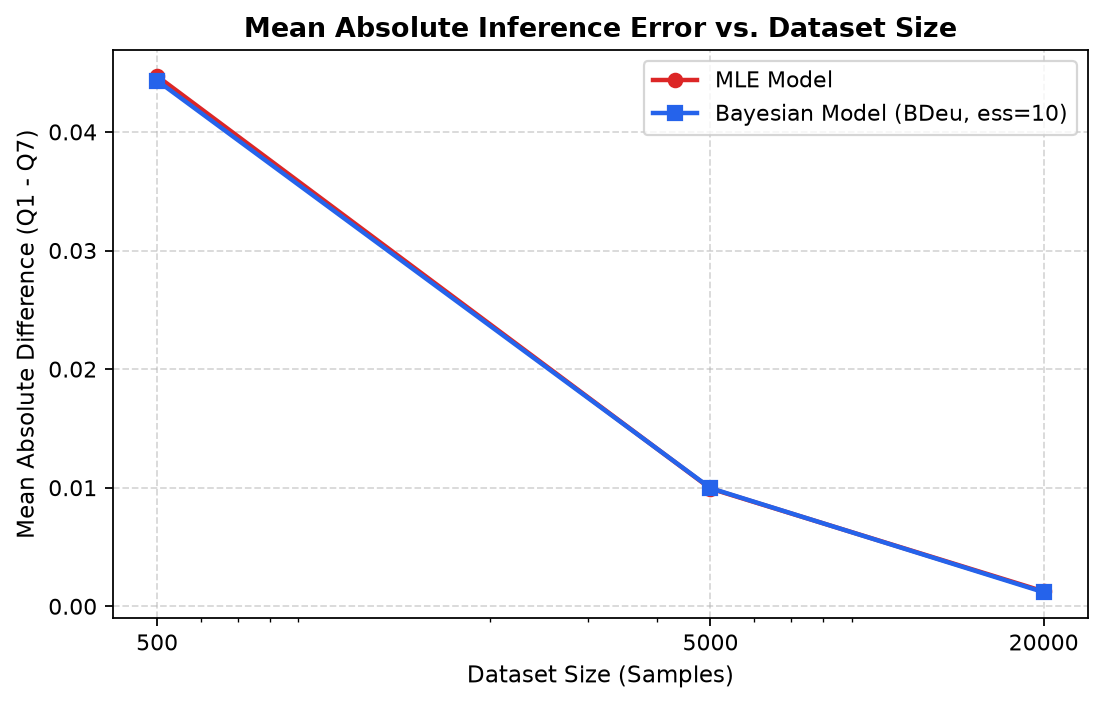

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=160)
ax.plot(sizes, err_mle, marker='o', lw=2, color='#dc2626', label='MLE Model')
ax.plot(sizes, err_bay, marker='s', lw=2, color='#2563eb', label='Bayesian Model (BDeu, ess=10)')
ax.set_xscale('log')
ax.set_xticks(sizes)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel('Dataset Size (Samples)', fontsize=10.5)
ax.set_ylabel('Mean Absolute Difference (Q1 - Q7)', fontsize=10.5)
ax.set_title('Mean Absolute Inference Error vs. Dataset Size', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.savefig('mad_vs_size.png', bbox_inches='tight')
plt.show()

### Part E Discussion
1. **Largest Error Query at $N = 500$:**
   Query **Q4** ($P(E = \text{High} \mid W = \text{Cold}, O = \text{High})$) exhibits the largest error (`0.0751` for MLE and `0.0761` for Bayesian). Its conditioning evidence $(W = \text{Cold}, O = \text{High})$ has a low joint prior probability of $0.20 \times 0.555 = 0.111$, resulting in only **61 samples** out of 500. With so few observations for this parent configuration, the learned parameter $P(A = \text{On} \mid \text{Cold}, \text{High})$ experiences larger sampling noise (`0.1475` vs. the expert value `0.1000`), which directly propagates into Q4's posterior estimate.
2. **Which Estimator Performs Better for Small Datasets and Why:**
   The **Bayesian estimator (BDeu with equivalent sample size $N' = 10$)** performs better on the 500-sample dataset, achieving a lower mean absolute error (`0.04433` vs. `0.04470` for MLE) and outperforming MLE on 4 of the 7 queries. When sample sizes are small, rare parent combinations suffer from high variance and can even produce zero-count probabilities under MLE. By adding uniform Dirichlet pseudo-counts ($\alpha = \frac{N'}{r \cdot q}$) to each cell, BDeu pulls noisy empirical ratios slightly toward a uniform prior, regularizing the CPT estimates until larger sample sizes ($N = 5000, 20000$) allow both estimators to converge closely to the true parameters.